# Stage 11 – Statistical validation

**Question.** Do the constructed driving cycles represent real driving in their environment?

**Independent test.** The cycles are compared with the **held-out trips** (set aside in Stage 9 and never
used to select or build a cycle). Comparing a cycle with the driving it was built from would be circular.

**What is compared (the methodology's list).**
- **Summary statistics:** mean, maximum and standard deviation of speed; mean acceleration and deceleration;
  acceleration standard deviation; share of time stopped, cruising, accelerating and decelerating;
  stop frequency; RPA.
- **Distributions:** speed bands, acceleration, and the joint **speed–acceleration frequency distribution
  (SAFD)**, the standard way to compare a cycle's overall driving pattern with real data.
- **Distance and duration** are reported for information only: a cycle is a fixed-length sample, so its
  length is a design choice, not something that can match.

**How "close enough" is judged (rules declared before looking at the results).**
1. **95 % confidence interval:** resample the held-out *trips* 1,000 times. If the cycle lies inside the CI,
   it is statistically indistinguishable from the held-out driving.
2. **Natural variation:** real trips differ from each other. If the cycle is within **1 trip-to-trip
   standard deviation**, it differs from the held-out driving no more than one real trip differs from another.
3. **Two baselines:** the cycle should be **at least as representative as a single real trip**, and
   **better than random cycles** of the same length made from random segments (no clustering or selection).

**Output** (`outputs/stage11_validation/`): validation tables, distribution comparisons, baselines, plots.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = Path("/content/drive/MyDrive/Colab Notebooks/Component01")
CYCLE_DIR = BASE / "outputs/stage10_driving_cycles"                 # Stage 10 cycles
SPLIT = BASE / "outputs/stage9_selection/trip_split.csv"             # Stage 9 construction / held-out split
SEG_DIR = BASE / "intermediate/stage6_segmented"                     # Stage 6: 1 Hz data with environment + segment
REPORT_DIR = BASE / "outputs/stage11_validation"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not SPLIT.exists():
    raise FileNotFoundError(f"{SPLIT} not found. Is Google Drive mounted, and have Stages 9-10 been run?")
split = pd.read_csv(SPLIT)
held_trips = split.loc[split["set"] == "held_out", "trip_id"].tolist()
con_trips = split.loc[split["set"] == "construction", "trip_id"].tolist()
cycles = {p.name.replace("_cycle_detailed.csv", ""): pd.read_csv(p) for p in sorted(CYCLE_DIR.glob("*_cycle_detailed.csv"))}
if not cycles:
    raise FileNotFoundError(f"No cycles in {CYCLE_DIR}. Has Stage 10 been run?")
data = {t: pd.read_csv(SEG_DIR / f"{t}.csv", usecols=["trip_id", "t_s", "speed_kmh", "environment", "seg_uid", "seg_quality"])
        for t in held_trips + con_trips}
print(f"Cycles: {list(cycles)} | held-out trips: {len(held_trips)} | construction trips: {len(con_trips)}")

Cycles: ['Expressway', 'Suburban', 'Urban'] | held-out trips: 23 | construction trips: 54


In [2]:
CFG = {
    # --- same definitions as Stages 6, 7 and 10
    "stop_kmh": 2.0, "min_stop_s": 3, "accel_threshold_ms2": 0.1,
    # --- which held-out driving counts
    "min_trip_env_s": 120,            # a held-out trip contributes a per-trip value only with >= 2 min in that environment
    # --- statistics compared (the methodology's list)
    "key_stats": ["mean_speed_kmh", "std_speed_kmh", "mean_pos_accel_ms2", "mean_neg_accel_ms2", "std_accel_ms2",
                  "idle_share", "cruise_share", "accel_share", "decel_share", "stops_per_km", "rpa_ms2"],
    # --- speed-acceleration frequency distribution (SAFD)
    "safd_speed_bins": list(range(0, 131, 10)),               # km/h
    "safd_accel_bins": list(np.round(np.arange(-3, 3.01, 0.25), 2)),   # m/s2 (values outside are put in the edge bins)
    "speed_bands": [0, 2, 10, 20, 30, 40, 50, 60, 70, 80, 90, 200],
    # --- uncertainty and baselines
    "n_bootstrap": 1000,              # resampling of held-out TRIPS for 95 % confidence intervals
    "n_random_cycles": 200,           # random cycles of the same length, built from random construction segments
    "random_state": 42,
    # --- pre-declared judgement rules (decided BEFORE looking at the results)
    "z_ok": 1.0,                      # a statistic is "within natural variation" if |cycle - held-out| <= 1 trip-to-trip SD
    "sd_floor_rel": 0.05,             # trip-to-trip SD is taken as at least 5 % of the held-out value
}
pd.Series(CFG, name="value").to_frame()

,value
stop_kmh,2.0
min_stop_s,3
accel_threshold_ms2,0.1
min_trip_env_s,120
key_stats,"[mean_speed_kmh, std_speed_kmh, mean_pos_accel..."
safd_speed_bins,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1..."
safd_accel_bins,"[-3.0, -2.75, -2.5, -2.25, -2.0, -1.75, -1.5, ..."
speed_bands,"[0, 2, 10, 20, 30, 40, 50, 60, 70, 80, 90, 200]"
n_bootstrap,1000
n_random_cycles,200


In [3]:
SB, AB = np.array(CFG["safd_speed_bins"]), np.array(CFG["safd_accel_bins"])


def suff(pieces):
    """Additive sums of a list of continuous speed pieces (km/h, 1 Hz). Sums of several trips can be added,
    which makes pooling and bootstrapping exact and fast. Definitions as in Stage 7."""
    S = dict(n=0, sv=0.0, sv2=0.0, idle=0, acc=0, dec=0, cru=0, stops=0, rpa=0.0,
             mov=0, sa=0.0, sa2=0.0, pos_n=0, pos_s=0.0, neg_n=0, neg_s=0.0, vmax=0.0)
    H = np.zeros((len(SB) - 1, len(AB) - 1))
    for v in pieces:
        v = np.asarray(v, float)
        ms = v / 3.6
        a = np.gradient(ms) if len(v) > 1 else np.zeros(len(v))
        moving = v >= CFG["stop_kmh"]
        th = CFG["accel_threshold_ms2"]
        acc, dec = moving & (a >= th), moving & (a <= -th)
        still = np.r_[False, ~moving, False].astype(int)
        d = np.diff(still)
        S["n"] += len(v); S["sv"] += v.sum(); S["sv2"] += (v ** 2).sum()
        S["idle"] += int((~moving).sum()); S["acc"] += int(acc.sum()); S["dec"] += int(dec.sum())
        S["cru"] += int((moving & (np.abs(a) < th)).sum())
        S["stops"] += int(((np.where(d == -1)[0] - np.where(d == 1)[0]) >= CFG["min_stop_s"]).sum())
        S["rpa"] += float((ms * np.clip(a, 0, None)).sum())
        S["mov"] += int(moving.sum()); S["sa"] += float(a[moving].sum()); S["sa2"] += float((a[moving] ** 2).sum())
        S["pos_n"] += int(acc.sum()); S["pos_s"] += float(a[acc].sum())
        S["neg_n"] += int(dec.sum()); S["neg_s"] += float(a[dec].sum())
        S["vmax"] = max(S["vmax"], float(v.max()) if len(v) else 0.0)
        H += np.histogram2d(np.clip(v, SB[0], SB[-1] - 1e-6), np.clip(a, AB[0], AB[-1] - 1e-6), bins=[SB, AB])[0]
    return S, H


def add(parts):
    S = {k: (max(p[0][k] for p in parts) if k == "vmax" else sum(p[0][k] for p in parts)) for k in parts[0][0]}
    return S, sum(p[1] for p in parts)


def stats(S):
    n, km = S["n"], S["sv"] / 3600
    mean = S["sv"] / n
    ma = S["sa"] / S["mov"] if S["mov"] else 0.0
    return pd.Series({
        "duration_s": n, "distance_km": km, "mean_speed_kmh": mean,
        "std_speed_kmh": np.sqrt(max(S["sv2"] / n - mean ** 2, 0)), "max_speed_kmh": S["vmax"],
        "mean_pos_accel_ms2": S["pos_s"] / S["pos_n"] if S["pos_n"] else 0.0,
        "mean_neg_accel_ms2": S["neg_s"] / S["neg_n"] if S["neg_n"] else 0.0,
        "std_accel_ms2": np.sqrt(max(S["sa2"] / S["mov"] - ma ** 2, 0)) if S["mov"] else 0.0,
        "idle_share": S["idle"] / n, "cruise_share": S["cru"] / n, "accel_share": S["acc"] / n, "decel_share": S["dec"] / n,
        "stops_per_km": S["stops"] / km if km else np.nan, "rpa_ms2": S["rpa"] / (km * 1000) if km else np.nan,
    })


def safd_diff(H1, H2):
    """SAFD difference (%): sum over all speed-acceleration cells of |share in 1 - share in 2| x 100 (0 = identical, 200 = no overlap)."""
    return float(np.abs(H1 / H1.sum() - H2 / H2.sum()).sum() * 100)


def pieces_of(trip, env):
    d = data[trip]
    d = d[(d["environment"] == env) & d["seg_uid"].notna() & (d["seg_quality"] != "exclude")]
    return [g.sort_values("t_s")["speed_kmh"].values.astype(float) for _, g in d.groupby("seg_uid", sort=False)]

In [4]:
rng = np.random.default_rng(CFG["random_state"])
results, stat_rows, per_trip_tables = {}, [], {}
for e, cyc in cycles.items():
    # held-out driving of this environment, per trip
    trip_parts = {t: suff(p) for t in held_trips if (p := pieces_of(t, e))}
    if not trip_parts:
        print(f"{e}: no held-out driving in this environment -> cannot be validated"); continue
    pooled = add(list(trip_parts.values()))
    held = stats(pooled[0])
    big = [t for t, p in trip_parts.items() if p[0]["n"] >= CFG["min_trip_env_s"]]
    per_trip = pd.DataFrame({t: stats(trip_parts[t][0]) for t in big}).T
    per_trip_tables[e] = per_trip
    sd = per_trip[CFG["key_stats"]].std() if len(big) >= 3 else pd.Series(np.nan, index=CFG["key_stats"])
    # floor: at least 5 % of the held-out value, so near-identical trips cannot make tiny differences look huge
    sd = pd.Series(np.fmax(sd.values, CFG["sd_floor_rel"] * held[CFG["key_stats"]].abs().values), index=CFG["key_stats"])

    # the cycle, with exactly the same definitions
    cS, cH = suff([cyc["speed_kmh"].values])
    cst = stats(cS)

    # 95 % CI of the held-out value: resample held-out TRIPS with replacement
    keys = list(trip_parts)
    boot = pd.DataFrame([stats(add([trip_parts[keys[i]] for i in rng.integers(0, len(keys), len(keys))])[0])
                         for _ in range(CFG["n_bootstrap"])])
    lo, hi = boot.quantile(0.025), boot.quantile(0.975)

    for s in CFG["key_stats"]:
        z = abs(cst[s] - held[s]) / sd[s] if sd[s] > 0 else np.nan
        stat_rows.append({"environment": e, "statistic": s, "cycle": cst[s], "held_out": held[s],
                          "difference_%": 100 * (cst[s] - held[s]) / held[s] if held[s] else np.nan,
                          "held_out_CI95": f"[{lo[s]:.3g}, {hi[s]:.3g}]", "cycle_inside_CI95": bool(lo[s] <= cst[s] <= hi[s]),
                          "trip_to_trip_SD": sd[s], "z": z,
                          "verdict": ("inside 95 % CI" if lo[s] <= cst[s] <= hi[s] else
                                      "within natural variation" if z <= CFG["z_ok"] else "outside natural variation")})
    # maximum speed: compared with the maximum of individual held-out trips (a pooled maximum is meaningless)
    mx = per_trip["max_speed_kmh"] if len(big) else pd.Series([held["max_speed_kmh"]])
    stat_rows.append({"environment": e, "statistic": "max_speed_kmh", "cycle": cst["max_speed_kmh"],
                      "held_out": mx.median(), "difference_%": 100 * (cst["max_speed_kmh"] - mx.median()) / mx.median(),
                      "held_out_CI95": f"trips: [{mx.min():.3g}, {mx.max():.3g}]",
                      "cycle_inside_CI95": bool(mx.min() <= cst["max_speed_kmh"] <= mx.max()),
                      "trip_to_trip_SD": mx.std(), "z": abs(cst["max_speed_kmh"] - mx.median()) / mx.std() if mx.std() > 0 else np.nan,
                      "verdict": "within the range of held-out trips" if mx.min() <= cst["max_speed_kmh"] <= mx.max() else "outside trip range"})
    results[e] = {"cycle": cst, "held": held, "cH": cH, "hH": pooled[1], "trip_parts": trip_parts, "sd": sd, "big": big,
                  "cyc_speed": cyc["speed_kmh"].values,
                  "held_speed": np.concatenate([np.concatenate(pieces_of(t, e)) for t in trip_parts])}
    print(f"{e:10s}: held-out driving {held['duration_s'] / 3600:.2f} h from {len(trip_parts)} trips "
          f"({len(big)} with >= {CFG['min_trip_env_s']} s) | cycle {int(cst['duration_s'])} s")

stat_table = pd.DataFrame(stat_rows)
stat_table.round(4).to_csv(REPORT_DIR / "validation_statistics.csv", index=False)
show = stat_table.copy()
for c in ["cycle", "held_out", "difference_%", "trip_to_trip_SD", "z"]:
    show[c] = show[c].astype(float).round(3)
show

Expressway: held-out driving 5.10 h from 12 trips (12 with >= 120 s) | cycle 1699 s
Suburban  : held-out driving 0.59 h from 21 trips (7 with >= 120 s) | cycle 593 s
Urban     : held-out driving 6.85 h from 22 trips (11 with >= 120 s) | cycle 1216 s


,environment,statistic,cycle,held_out,difference_%,held_out_CI95,cycle_inside_CI95,trip_to_trip_SD,z,verdict
0,Expressway,mean_speed_kmh,76.812,76.862,-0.065,"[75.5, 78.1]",True,3.843,0.013,inside 95 % CI
1,Expressway,std_speed_kmh,25.166,24.011,4.811,"[23, 25.1]",False,1.650,0.700,within natural variation
2,Expressway,mean_pos_accel_ms2,0.395,0.362,9.085,"[0.33, 0.387]",False,0.046,0.714,within natural variation
3,Expressway,mean_neg_accel_ms2,-0.429,-0.397,7.999,"[-0.427, -0.365]",False,0.048,0.658,within natural variation
4,Expressway,std_accel_ms2,0.313,0.310,1.015,"[0.286, 0.337]",True,0.041,0.076,inside 95 % CI
5,Expressway,idle_share,0.032,0.030,9.659,"[0.0242, 0.0337]",True,0.011,0.265,inside 95 % CI
6,Expressway,cruise_share,0.725,0.672,7.801,"[0.637, 0.704]",False,0.056,0.938,within natural variation
7,Expressway,accel_share,0.124,0.155,-19.826,"[0.138, 0.173]",False,0.030,1.030,outside natural variation
8,Expressway,decel_share,0.119,0.143,-17.127,"[0.13, 0.157]",False,0.024,1.007,outside natural variation
9,Expressway,stops_per_km,0.055,0.056,-1.697,"[0.0484, 0.0608]",True,0.017,0.054,inside 95 % CI


In [5]:
dist_rows = []
for e, r in results.items():
    # speed distribution (time share per speed band)
    b = CFG["speed_bands"]
    pc = np.histogram(r["cyc_speed"], bins=b)[0] / len(r["cyc_speed"])
    ph = np.histogram(r["held_speed"], bins=b)[0] / len(r["held_speed"])
    # acceleration distribution (moving seconds), from the SAFD marginal
    ac, ah = r["cH"].sum(axis=0), r["hH"].sum(axis=0)
    dist_rows.append({
        "environment": e,
        "speed_band_difference_%": round(100 * np.abs(pc - ph).sum(), 1),
        "speed_KS_D": round(ks_2samp(r["cyc_speed"], r["held_speed"]).statistic, 3),
        "accel_distribution_difference_%": round(100 * np.abs(ac / ac.sum() - ah / ah.sum()).sum(), 1),
        "SAFD_difference_%": round(safd_diff(r["cH"], r["hH"]), 1),
    })
    r["speed_band_cycle"], r["speed_band_held"] = pc, ph
dist = pd.DataFrame(dist_rows).set_index("environment")
dist.to_csv(REPORT_DIR / "validation_distributions.csv")
print("Distribution comparisons (0 = identical). KS D is reported as an effect size only: with thousands of")
print("autocorrelated 1 Hz samples a KS p-value would be meaningless, so none is used.")
dist

Distribution comparisons (0 = identical). KS D is reported as an effect size only: with thousands of
autocorrelated 1 Hz samples a KS p-value would be meaningless, so none is used.


,speed_band_difference_%,speed_KS_D,accel_distribution_difference_%,SAFD_difference_%
environment,,,,
Expressway,15.2,0.065,4.9,21.1
Suburban,22.3,0.083,21.7,44.1
Urban,39.0,0.173,5.2,40.2


In [6]:
# What does "good" look like? Two baselines with the SAME error measures:
#  (1) natural variability: each held-out trip vs. all OTHER held-out trips (how representative is one real trip?)
#  (2) random cycles: random construction segments of the same total length (no clustering, no selection)
def composite(st, ref, sd):
    z = [(abs(st[s] - ref[s]) / sd[s]) for s in CFG["key_stats"] if sd[s] > 0]
    return float(np.mean(z)) if z else np.nan

base_rows = []
for e, r in results.items():
    tp, sd = r["trip_parts"], r["sd"]
    cyc_score = composite(r["cycle"], r["held"], sd)
    cyc_safd = safd_diff(r["cH"], r["hH"])
    # (1) leave-one-trip-out
    trip_scores, trip_safd = [], []
    for t in r["big"]:
        rest = add([p for k, p in tp.items() if k != t])
        trip_scores.append(composite(stats(tp[t][0]), stats(rest[0]), sd))
        trip_safd.append(safd_diff(tp[t][1], rest[1]))
    # (2) random cycles from construction segments
    con_pieces = [p for t in con_trips for p in pieces_of(t, e)]
    rnd_scores, rnd_safd = [], []
    rr = np.random.default_rng(CFG["random_state"])
    for _ in range(CFG["n_random_cycles"]):
        pick, tot = [], 0
        for i in rr.permutation(len(con_pieces)):
            pick.append(con_pieces[i]); tot += len(con_pieces[i])
            if tot >= r["cycle"]["duration_s"]:
                break
        S, H = suff(pick)
        rnd_scores.append(composite(stats(S), r["held"], sd)); rnd_safd.append(safd_diff(H, r["hH"]))
    rnd_scores, rnd_safd = np.array(rnd_scores), np.array(rnd_safd)
    base_rows.append({
        "environment": e,
        "cycle_mean_|z|": round(cyc_score, 3),
        "single_trip_median_|z|": round(float(np.median(trip_scores)), 3) if trip_scores else np.nan,
        "random_cycle_median_|z|": round(float(np.nanmedian(rnd_scores)), 3),
        "cycle_better_than_random_%": round(100 * float(np.mean(rnd_scores > cyc_score)), 1),
        "cycle_SAFD_diff_%": round(cyc_safd, 1),
        "single_trip_median_SAFD_%": round(float(np.median(trip_safd)), 1) if trip_safd else np.nan,
        "random_cycle_median_SAFD_%": round(float(np.median(rnd_safd)), 1),
        "SAFD_better_than_random_%": round(100 * float(np.mean(rnd_safd > cyc_safd)), 1),
    })
    r["rnd_scores"], r["trip_scores"] = rnd_scores, trip_scores
baselines = pd.DataFrame(base_rows).set_index("environment")
baselines.to_csv(REPORT_DIR / "validation_baselines.csv")
print("mean |z| = average distance from the held-out value over all key statistics, in trip-to-trip SDs (lower = better)")
baselines

mean |z| = average distance from the held-out value over all key statistics, in trip-to-trip SDs (lower = better)


,cycle_mean_|z|,single_trip_median_|z|,random_cycle_median_|z|,cycle_better_than_random_%,cycle_SAFD_diff_%,single_trip_median_SAFD_%,random_cycle_median_SAFD_%,SAFD_better_than_random_%
environment,,,,,,,,
Expressway,0.556,0.660,1.198,95.0,21.1,32.7,37.7,98.0
Suburban,0.123,0.897,0.418,99.5,44.1,91.0,44.2,50.0
Urban,0.544,0.812,0.821,83.0,40.2,46.6,36.7,39.0


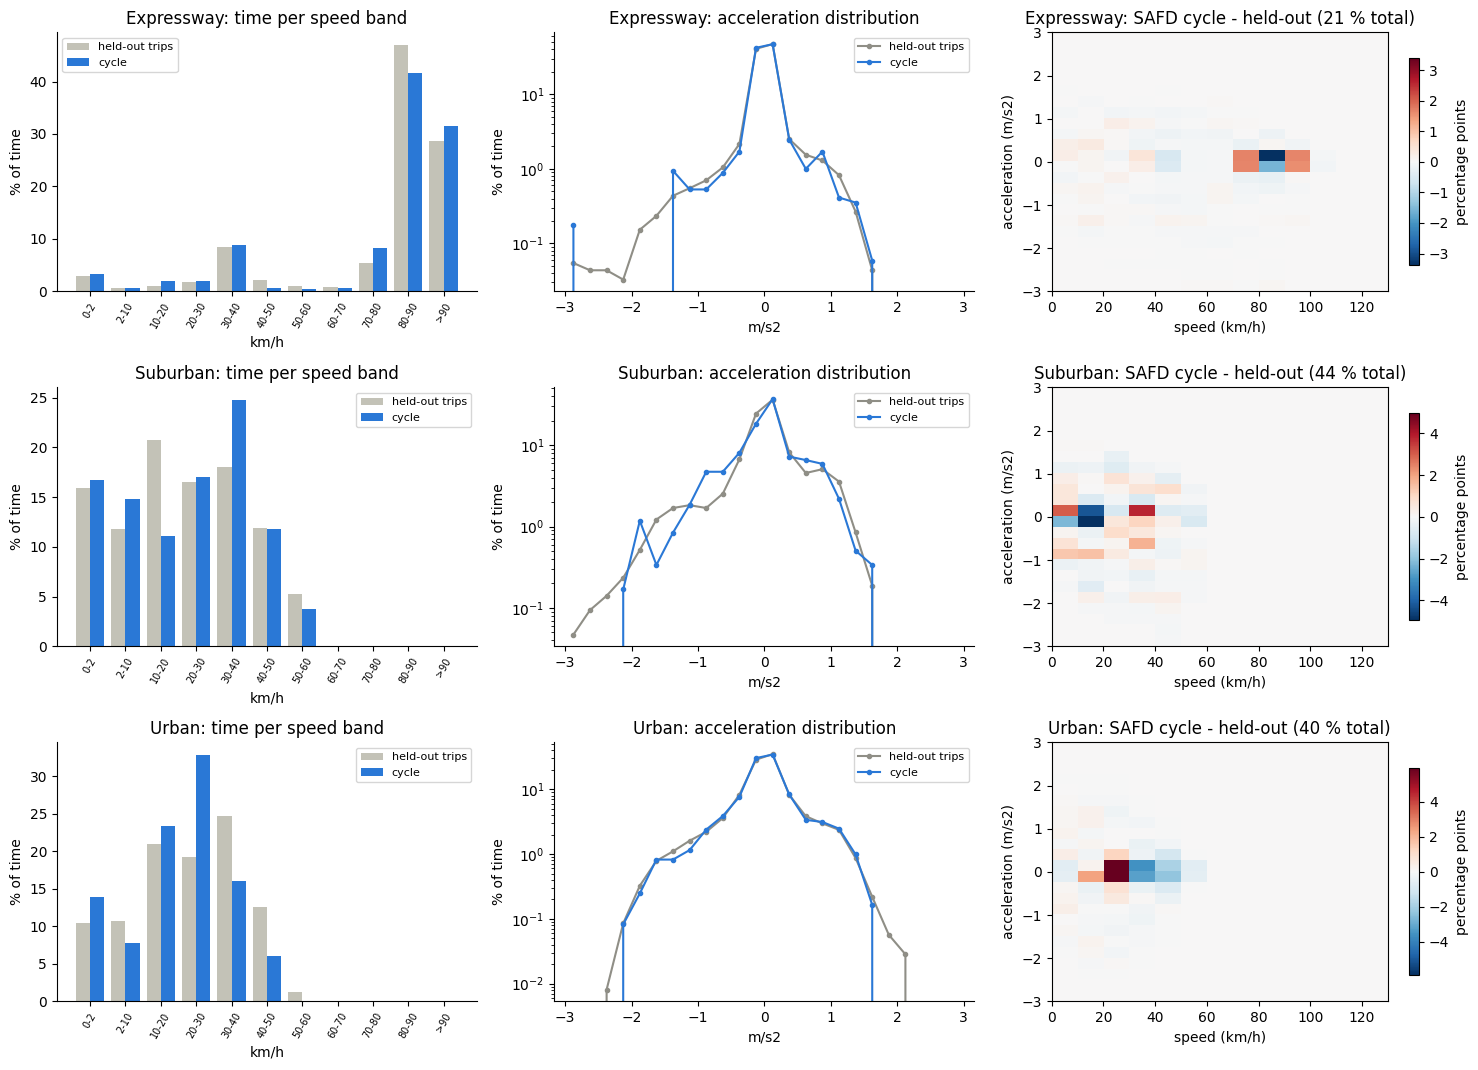

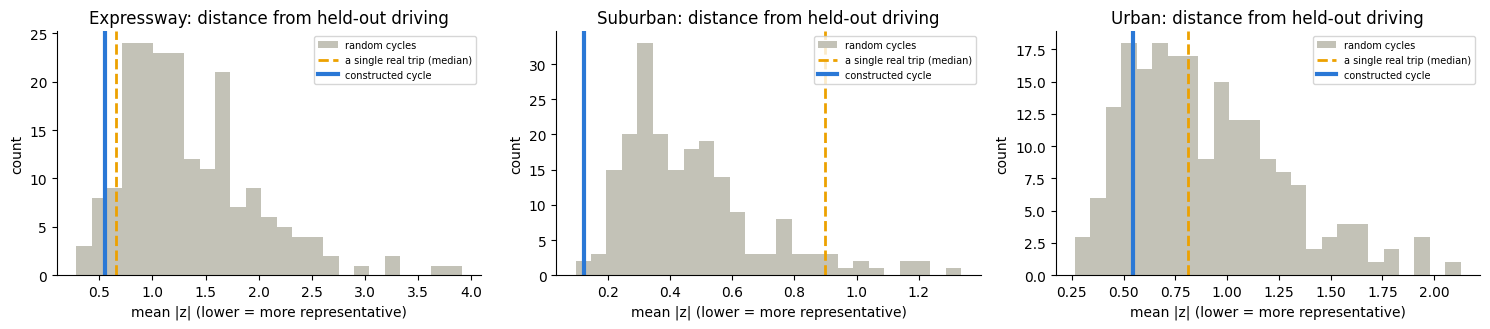

In [7]:
envs = list(results)
fig, axes = plt.subplots(len(envs), 3, figsize=(15, 3.6 * len(envs)), squeeze=False)
for row, e in zip(axes, envs):
    r = results[e]
    # 1. speed distribution
    b = CFG["speed_bands"]
    lab = [f"{b[i]}-{b[i + 1]}" if b[i + 1] < 200 else f">{b[i]}" for i in range(len(b) - 1)]
    x = np.arange(len(lab))
    row[0].bar(x - 0.2, 100 * r["speed_band_held"], 0.4, color="#c3c2b7", label="held-out trips")
    row[0].bar(x + 0.2, 100 * r["speed_band_cycle"], 0.4, color="#2a78d6", label="cycle")
    row[0].set_xticks(x, lab, rotation=60, fontsize=7)
    row[0].set(title=f"{e}: time per speed band", xlabel="km/h", ylabel="% of time")
    row[0].legend(fontsize=8)
    # 2. acceleration distribution
    centres = (AB[:-1] + AB[1:]) / 2
    ac, ah = r["cH"].sum(axis=0), r["hH"].sum(axis=0)
    row[1].plot(centres, 100 * ah / ah.sum(), "o-", color="#8f8e86", ms=3, label="held-out trips")
    row[1].plot(centres, 100 * ac / ac.sum(), "o-", color="#2a78d6", ms=3, label="cycle")
    row[1].set(title=f"{e}: acceleration distribution", xlabel="m/s2", ylabel="% of time", yscale="log")
    row[1].legend(fontsize=8)
    # 3. SAFD difference map
    diff = 100 * (r["cH"] / r["cH"].sum() - r["hH"] / r["hH"].sum())
    lim = max(np.abs(diff).max(), 0.1)
    im = row[2].imshow(diff.T, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim,
                       extent=[SB[0], SB[-1], AB[0], AB[-1]])
    row[2].set(title=f"{e}: SAFD cycle - held-out ({safd_diff(r['cH'], r['hH']):.0f} % total)",
               xlabel="speed (km/h)", ylabel="acceleration (m/s2)")
    fig.colorbar(im, ax=row[2], shrink=0.8, label="percentage points")
    for ax in row[:2]:
        ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "validation_distributions.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, len(envs), figsize=(5 * len(envs), 3.4), squeeze=False)
for ax, e in zip(axes[0], envs):
    r = results[e]
    ax.hist(r["rnd_scores"], bins=25, color="#c3c2b7", label="random cycles")
    if r["trip_scores"]:
        ax.axvline(np.median(r["trip_scores"]), color="#eda100", ls="--", lw=2, label="a single real trip (median)")
    ax.axvline(baselines.loc[e, "cycle_mean_|z|"], color="#2a78d6", lw=3, label="constructed cycle")
    ax.set(title=f"{e}: distance from held-out driving", xlabel="mean |z| (lower = more representative)", ylabel="count")
    ax.legend(fontsize=7)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "validation_baselines.png", dpi=150)
plt.show()

In [8]:
checks = {}
held_set = set(held_trips)
used = {s.rsplit("_S", 1)[0] for c in cycles.values() for s in c["source"].unique() if s != "transition"}
checks["no cycle segment comes from a held-out trip"] = not (used & held_set)
checks["held-out and construction trips are disjoint"] = not (set(held_trips) & set(con_trips))
s10 = pd.read_csv(CYCLE_DIR / "cycle_vs_construction_driving.csv")
checks["cycle statistics identical to Stage 10 (mean speed, idle share)"] = all(
    abs(results[e]["cycle"][s] - s10[(s10["environment"] == e) & (s10["statistic"] == s)]["cycle"].iat[0]) < 1e-2
    for e in results for s in ("mean_speed_kmh", "idle_share"))
checks["pooled held-out mean speed = simple mean of all held-out seconds"] = all(
    abs(results[e]["held"]["mean_speed_kmh"] - results[e]["held_speed"].mean()) < 1e-6 for e in results)
checks["SAFD covers every second (counts = duration)"] = all(
    results[e]["cH"].sum() == results[e]["cycle"]["duration_s"] and results[e]["hH"].sum() == results[e]["held"]["duration_s"]
    for e in results)
checks["key statistics computed for every validated environment"] = (
    stat_table.groupby("environment")["statistic"].nunique() == len(CFG["key_stats"]) + 1).all()
verification = pd.DataFrame({"result": ["PASS" if v else "CHECK" for v in checks.values()]}, index=checks.keys())
verification

,result
no cycle segment comes from a held-out trip,PASS
held-out and construction trips are disjoint,PASS
"cycle statistics identical to Stage 10 (mean speed, idle share)",PASS
pooled held-out mean speed = simple mean of all held-out seconds,PASS
SAFD covers every second (counts = duration),PASS
key statistics computed for every validated environment,PASS


In [10]:
print("STAGE 11 – STATISTICAL VALIDATION: KEY RESULTS (against held-out trips never used to build the cycles)")
print("-" * 100)
for e, r in results.items():
    t = stat_table[stat_table["environment"] == e]
    ok = t["verdict"].isin(["inside 95 % CI", "within natural variation", "within the range of held-out trips"])
    b = baselines.loc[e]
    print(f"{e}: {int(ok.sum())}/{len(t)} statistics inside the 95 % CI or within natural trip-to-trip variation")
    for _, x in t.iterrows():
        print(f"    {x['statistic']:20s} cycle {x['cycle']:8.3f} | held-out {x['held_out']:8.3f} "
              f"({x['difference_%']:+6.1f} %) -> {x['verdict']}")
    print(f"    SAFD difference {b['cycle_SAFD_diff_%']} % (single real trip {b['single_trip_median_SAFD_%']} %, "
          f"random cycle {b['random_cycle_median_SAFD_%']} %)")
    print(f"    overall distance mean|z| {b['cycle_mean_|z|']} (single real trip {b['single_trip_median_|z|']}, "
          f"random cycle {b['random_cycle_median_|z|']}); cycle better than {b['cycle_better_than_random_%']} % of random cycles")
print("Not validated (no cycle / no data): " + ", ".join(e for e in ["Urban", "Suburban", "Intercity", "Rural", "Expressway"]
                                                        if e not in results))
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 11 – STATISTICAL VALIDATION: KEY RESULTS (against held-out trips never used to build the cycles)
----------------------------------------------------------------------------------------------------
Expressway: 10/12 statistics inside the 95 % CI or within natural trip-to-trip variation
    mean_speed_kmh       cycle   76.812 | held-out   76.862 (  -0.1 %) -> inside 95 % CI
    std_speed_kmh        cycle   25.166 | held-out   24.011 (  +4.8 %) -> within natural variation
    mean_pos_accel_ms2   cycle    0.395 | held-out    0.362 (  +9.1 %) -> within natural variation
    mean_neg_accel_ms2   cycle   -0.429 | held-out   -0.397 (  +8.0 %) -> within natural variation
    std_accel_ms2        cycle    0.313 | held-out    0.310 (  +1.0 %) -> inside 95 % CI
    idle_share           cycle    0.032 | held-out    0.030 (  +9.7 %) -> inside 95 % CI
    cruise_share         cycle    0.725 | held-out    0.672 (  +7.8 %) -> within natural variation
    accel_share          cycle    0.124 | he